In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1: `Loading dataset from Kaggle`

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abiodunonadeji/united-state-superstore-sales")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'united-state-superstore-sales' dataset.
Path to dataset files: /kaggle/input/united-state-superstore-sales


In [3]:
df_original = pd.read_excel(f"{path}/Sample - Superstore.xls")
df = df_original.copy()

In [4]:
df.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
5,6,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
6,7,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,4,0.00,1.9656
7,8,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6,0.20,90.7152
8,9,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040,3,0.20,5.7825
9,10,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5,0.00,34.4700


In [5]:
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,2014-01-21,2014-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [6]:
df.groupby("Category")["Sub-Category"].value_counts()

Category         Sub-Category
Furniture        Furnishings      957
                 Chairs           617
                 Tables           319
                 Bookcases        228
Office Supplies  Binders         1523
                 Paper           1370
                 Storage          846
                 Art              796
                 Appliances       466
                 Labels           364
                 Envelopes        254
                 Fasteners        217
                 Supplies         190
Technology       Phones           889
                 Accessories      775
                 Machines         115
                 Copiers           68
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [8]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


# 2: `Cleaning the Dataset`
### Rules to Clean
- drop the unwanted features
- check for datatypes of features
- check for missing values
- check for duplicates
- check for values like Distance&Size can't be negative.
- check for outliers

In [9]:
df.head(1)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136


### 2.1) `Drop unwanted features`
- Row ID is just index so it is not required
- Customer Name is not required because we have Customer ID for uniqueness.
- Country is not required because country has only one value.

In [10]:
len(df["Product ID"].unique())

1862

In [11]:
df[df["Product ID"]=="FUR-FU-10000747"]["Product Name"]

,Product Name
5811,Tenex B1-RE Series Chair Mats for Low Pile Car...
6015,Tenex B1-RE Series Chair Mats for Low Pile Car...
7154,Tenex B1-RE Series Chair Mats for Low Pile Car...
8564,Tenex B1-RE Series Chair Mats for Low Pile Car...
9320,Tenex B1-RE Series Chair Mats for Low Pile Car...
9359,Tenex B1-RE Series Chair Mats for Low Pile Car...
9990,Tenex B1-RE Series Chair Mats for Low Pile Car...


- Product ID and Product Name are same thing so we remove Product Name

In [12]:
print(len(df["City"].unique()))
print(len(df["Region"].unique()))
print(len(df["Postal Code"].unique()))
print(len(df["State"].unique()))
df[df["City"]=="Los Angeles"]["Postal Code"]

531
4
631
49


,Postal Code
2,90036
5,90032
6,90032
7,90032
8,90032
...,...
9976,90032
9977,90032
9978,90032
9979,90032


In [13]:
df.drop(columns=["Row ID","Customer Name","Country","Product Name"], inplace = True)

## 2.2: `check for missing values`

In [14]:
df.isnull().sum()

,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Segment,0
City,0
State,0
Postal Code,0
Region,0


## 2.3: `Check for Duplicates`

In [15]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)

In [16]:
df.duplicated().sum()

np.int64(0)

## 2.4: `Check for values which can't be real`
- Sales can't be negative
- Quantity can't be negative or in decimal in this specific dataset

In [17]:
# check for negative value in Sales.
len(df[df["Sales"]<0])

0

In [18]:
# check for negative and decimal value in Quantity
len(df[(df["Quantity"]<0) | (df["Quantity"]%1!=0)])

0

## 2.5: `check for outliers`

In [19]:
df

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,731.9400,3,0.00,219.5820
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,957.5775,5,0.45,-383.0310
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,CA-2014-110422,2014-01-21,2014-01-23,Second Class,TB-21400,Consumer,Miami,Florida,33180,South,FUR-FU-10001889,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,Costa Mesa,California,92627,West,FUR-FU-10000747,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,Costa Mesa,California,92627,West,TEC-PH-10003645,Technology,Phones,258.5760,2,0.20,19.3932
9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,Costa Mesa,California,92627,West,OFF-PA-10004041,Office Supplies,Paper,29.6000,4,0.00,13.3200


### 2.5.1) `Visualizing Outliers with Boxplots`
We will plot boxplots for `Sales`, `Quantity`, `Discount`, and `Profit` to visually identify extreme values.

/tmp/ipykernel_932/2900153915.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[col], ax=axes[i], palette='Set2')
/tmp/ipykernel_932/2900153915.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[col], ax=axes[i], palette='Set2')
/tmp/ipykernel_932/2900153915.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[col], ax=axes[i], palette='Set2')
/tmp/ipykernel_932/2900153915.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `l

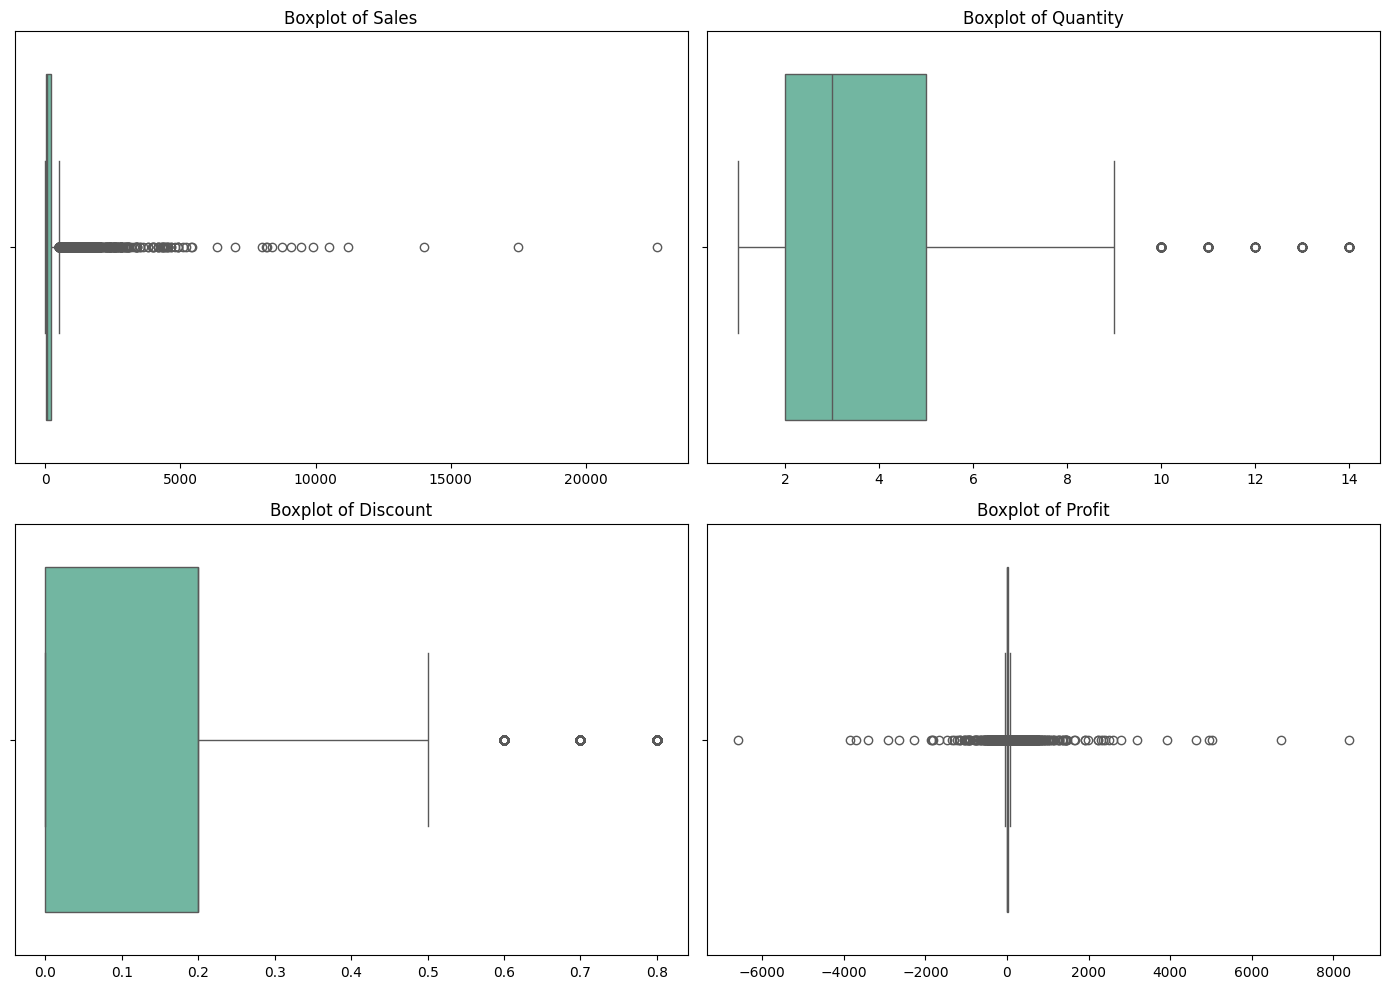

In [20]:
cols_to_check = ['Sales', 'Quantity', 'Discount', 'Profit']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cols_to_check):
    sns.boxplot(x=df[col], ax=axes[i], palette='Set2')
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

### 2.5.2: `Statistical Detection of Outliers (IQR Method)`
Let's calculate the number of outliers and their percentage in the dataset for each of these numerical columns.

In [21]:
for col in cols_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers detected ({len(outliers)/len(df)*100:.2f}% of data)")
    print(f"  Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}\n")
    cleaned_df = df[(df[col]>lower_bound) & (df[col]<upper_bound)]

Sales: 1167 outliers detected (11.68% of data)
  Lower Bound: -271.71, Upper Bound: 498.93

Quantity: 170 outliers detected (1.70% of data)
  Lower Bound: -2.50, Upper Bound: 9.50

Discount: 856 outliers detected (8.57% of data)
  Lower Bound: -0.30, Upper Bound: 0.50

Profit: 1881 outliers detected (18.82% of data)
  Lower Bound: -39.72, Upper Bound: 70.81



In [22]:
# After removed of Outliers
cleaned_df.shape

(8112, 17)

# 3: `Visualization`
- `Histogram`. Show how your main number column is spread out. Is it balanced or skewed to one side?
- `Count plot`. Show how many rows fall in each category of a categorical column.
- `Box plot`. Compare your main number column across groups (for example body mass by species, or price by cut).
- `Scatter plot`. Plot two number columns against each other, coloured by a category. Do they move together?
- `Trend`. Show how something changes over time with a line chart (mpg: model year, planets: discovery year, taxis: pickup hour). If your dataset has no time column, make a bar chart of averages by group.
- `Heatmap`. Make a correlation heatmap of the number columns. Which two columns have the strongest relationship?

## 3.1: `Histogram`
- Is it balanced or skewed to one side

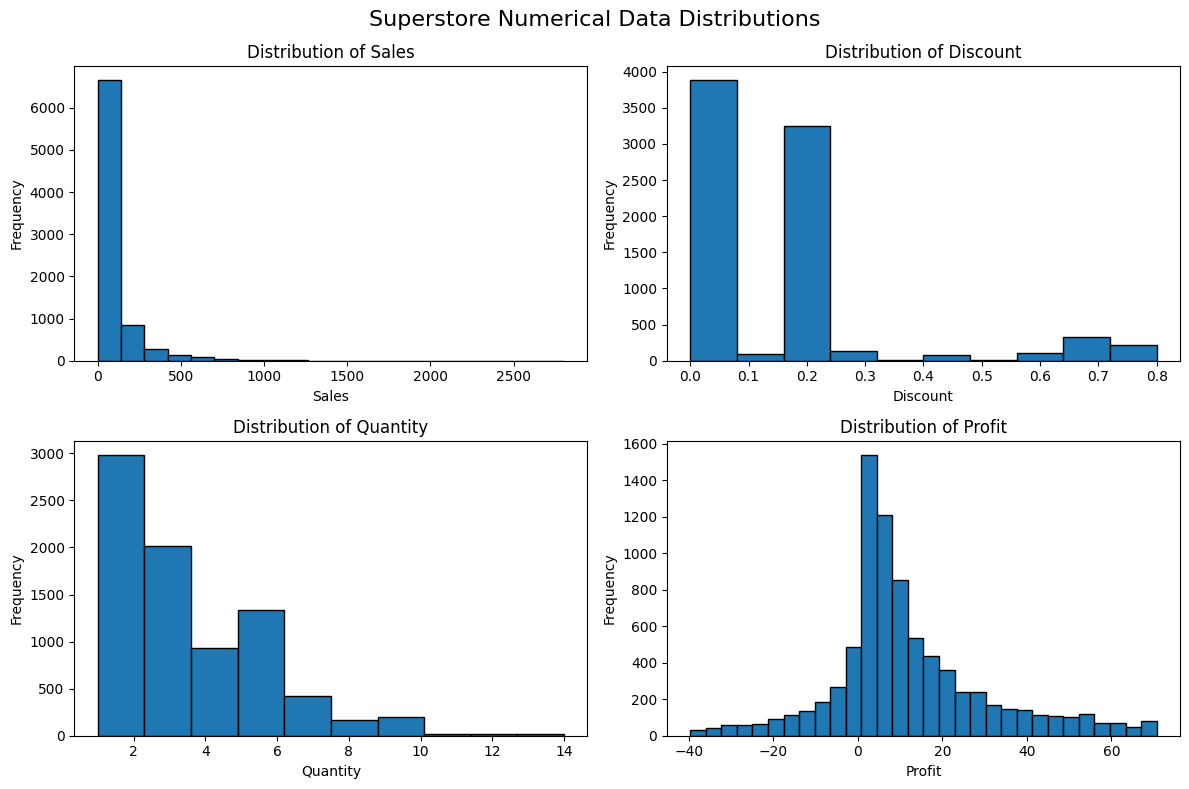

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
# Histogram 1: Sales
ax[0, 0].hist(cleaned_df["Sales"], bins=20, edgecolor="black")
ax[0, 0].set_title("Distribution of Sales")
ax[0, 0].set_xlabel("Sales")
ax[0, 0].set_ylabel("Frequency")

# Histogram 2: Discount
ax[0, 1].hist(cleaned_df["Discount"], bins=10, edgecolor="black")
ax[0, 1].set_title("Distribution of Discount")
ax[0, 1].set_xlabel("Discount")
ax[0, 1].set_ylabel("Frequency")

# Histogram 3: Quantity
ax[1, 0].hist(cleaned_df["Quantity"], bins=10, edgecolor="black")
ax[1, 0].set_title("Distribution of Quantity")
ax[1, 0].set_xlabel("Quantity")
ax[1, 0].set_ylabel("Frequency")

# Histogram 4: Profit
ax[1, 1].hist(cleaned_df["Profit"], bins=30, edgecolor="black")
ax[1, 1].set_title("Distribution of Profit")
ax[1, 1].set_xlabel("Profit")
ax[1, 1].set_ylabel("Frequency")

fig.suptitle("Superstore Numerical Data Distributions", fontsize=16)
plt.tight_layout()
plt.show()

## 3.2: `Count plot`

In [24]:
print(cleaned_df["Category"].value_counts())

Category
Office Supplies    5341
Furniture          1493
Technology         1278
Name: count, dtype: int64


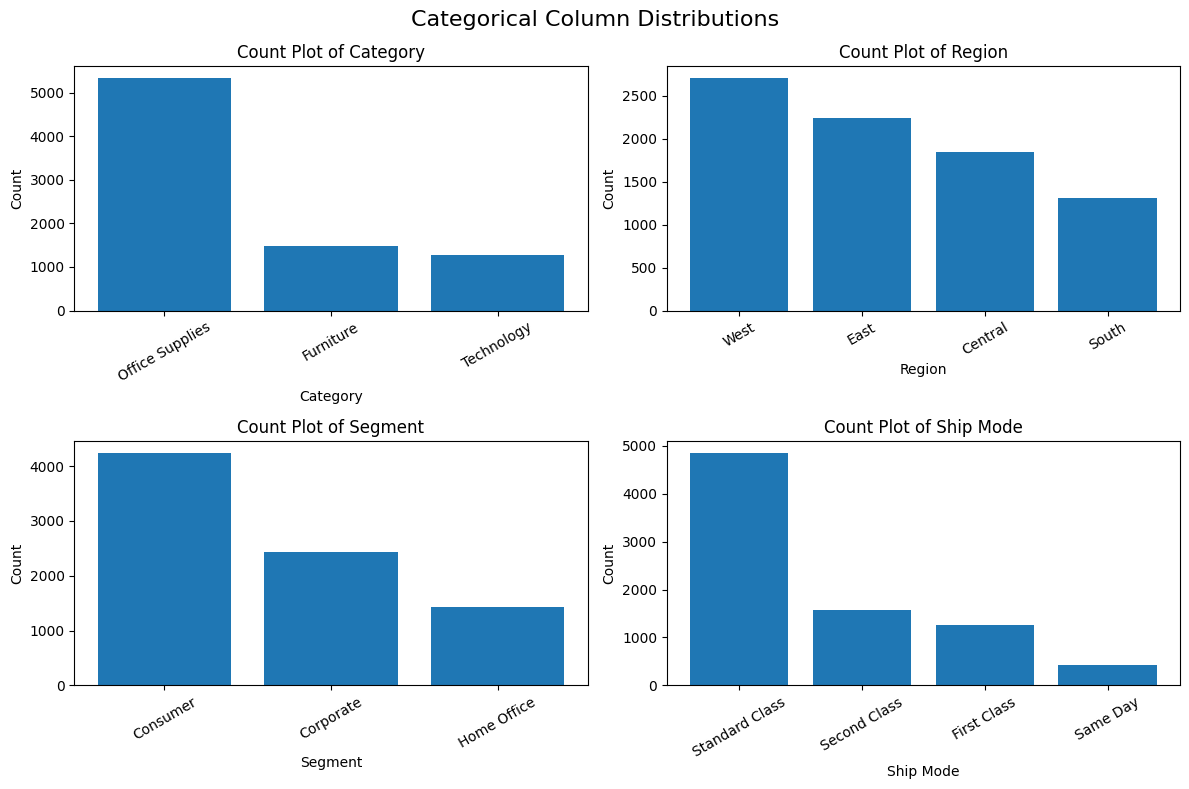

In [25]:
categorical_cols = ["Category", "Region", "Segment", "Ship Mode"]

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(categorical_cols):
    counts = cleaned_df[col].value_counts()

    ax[i // 2, i % 2].bar(counts.index, counts.values)
    ax[i // 2, i % 2].set_title(f"Count Plot of {col}")
    ax[i // 2, i % 2].set_xlabel(col)
    ax[i // 2, i % 2].set_ylabel("Count")
    ax[i // 2, i % 2].tick_params(axis="x", rotation=30)

fig.suptitle("Categorical Column Distributions", fontsize=16)
plt.tight_layout()
plt.show()

## 3.3: `Box Plot`

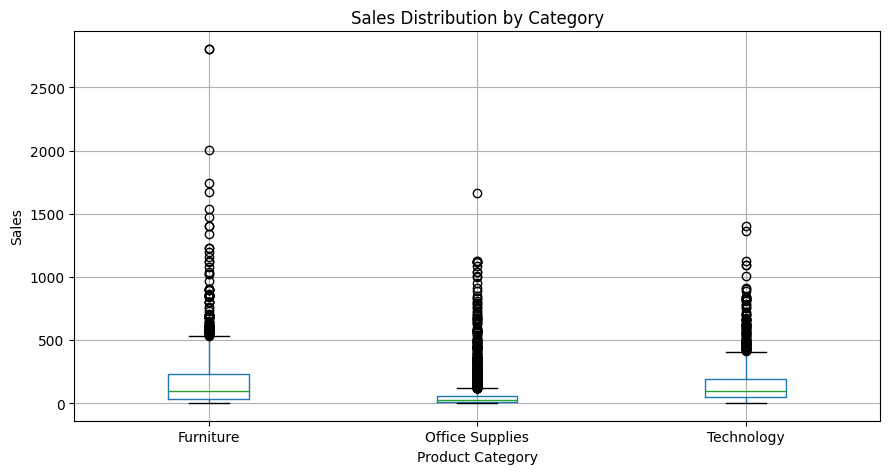

In [31]:
fig, ax = plt.subplots(figsize=(9, 5))

cleaned_df.boxplot(
    column="Sales",
    by="Category",
    ax=ax
)

ax.set_title("Sales Distribution by Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Sales")
fig.suptitle("")

plt.tight_layout()
plt.show()

## 3.4: `Scatter Plot`

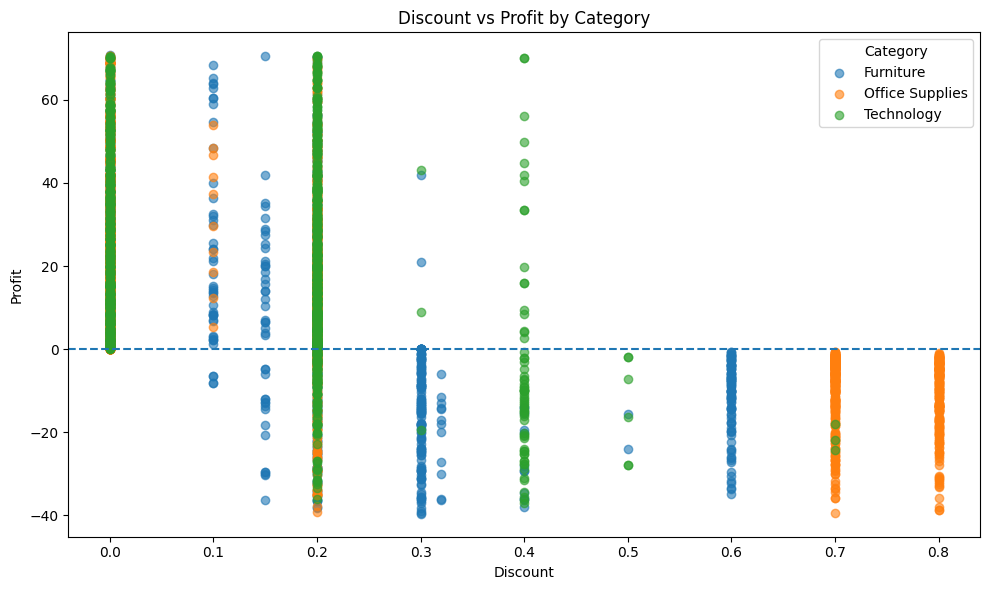

Correlation: -0.4313583311019947


In [27]:

fig, ax = plt.subplots(figsize=(10, 6))

# Plot each category in a different color
for category in cleaned_df["Category"].unique():
    subset = cleaned_df[cleaned_df["Category"] == category]

    ax.scatter(
        subset["Discount"],
        subset["Profit"],
        label=category,
        alpha=0.6
    )

ax.set_title("Discount vs Profit by Category")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit")
ax.legend(title="Category")
ax.axhline(y=0, linestyle="--")

plt.tight_layout()
plt.show()

# Calculate correlation
print("Correlation:", cleaned_df["Discount"].corr(cleaned_df["Profit"]))

## 3.5: `Trend`

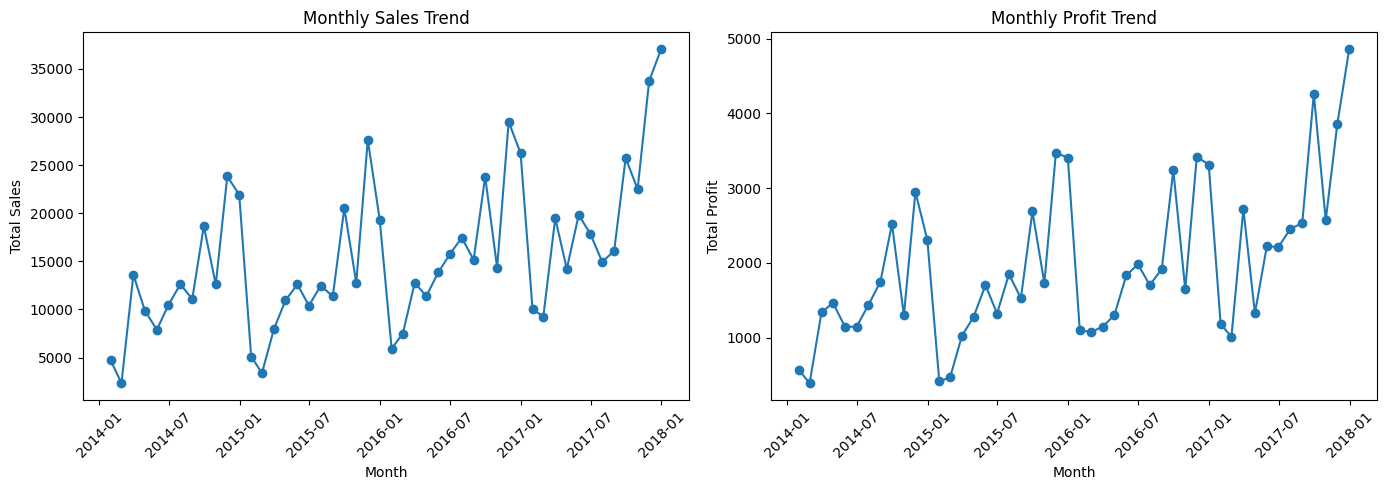

In [28]:
monthly_data = (
    cleaned_df.dropna(subset=["Order Date"])
    .set_index("Order Date")[["Sales", "Profit"]]
    .resample("ME")
    .sum()
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(monthly_data.index, monthly_data["Sales"], marker="o")
ax[0].set_title("Monthly Sales Trend")
ax[0].set_xlabel("Month")
ax[0].set_ylabel("Total Sales")
ax[0].tick_params(axis="x", rotation=45)

ax[1].plot(monthly_data.index, monthly_data["Profit"], marker="o")
ax[1].set_title("Monthly Profit Trend")
ax[1].set_xlabel("Month")
ax[1].set_ylabel("Total Profit")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

`Category-wise Sales by Order Date`

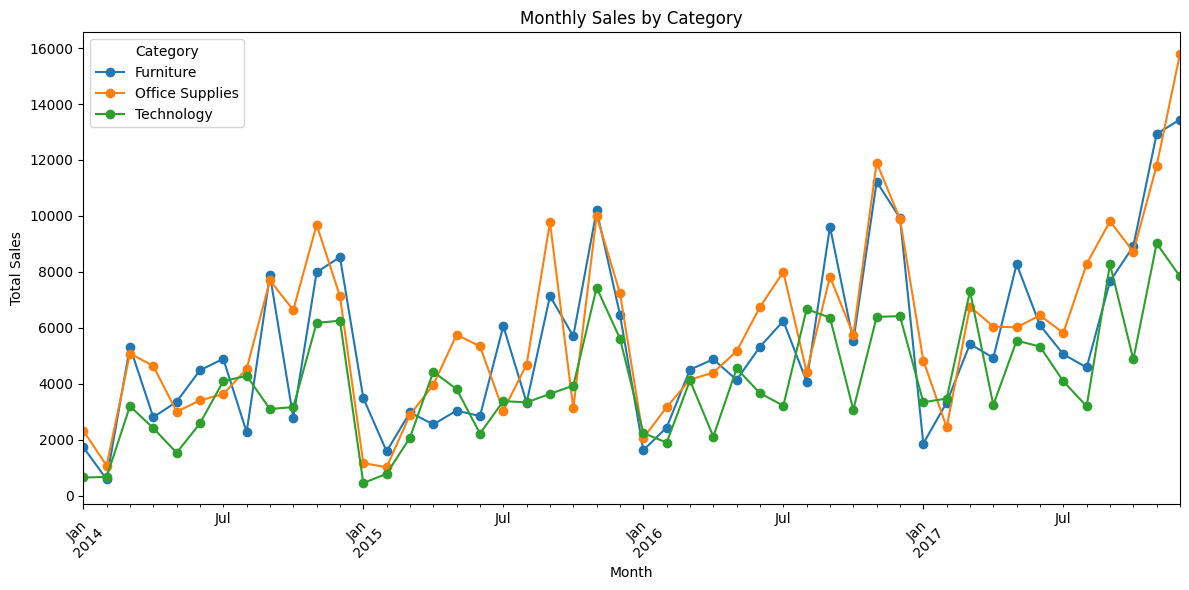

In [29]:
monthly_category_sales = (
    cleaned_df.dropna(subset=["Order Date"])
    .groupby([
        pd.Grouper(key="Order Date", freq="ME"),
        "Category"
    ])["Sales"]
    .sum()
    .unstack()
)

fig, ax = plt.subplots(figsize=(12, 6))

monthly_category_sales.plot(ax=ax, marker="o")

ax.set_title("Monthly Sales by Category")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.legend(title="Category")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

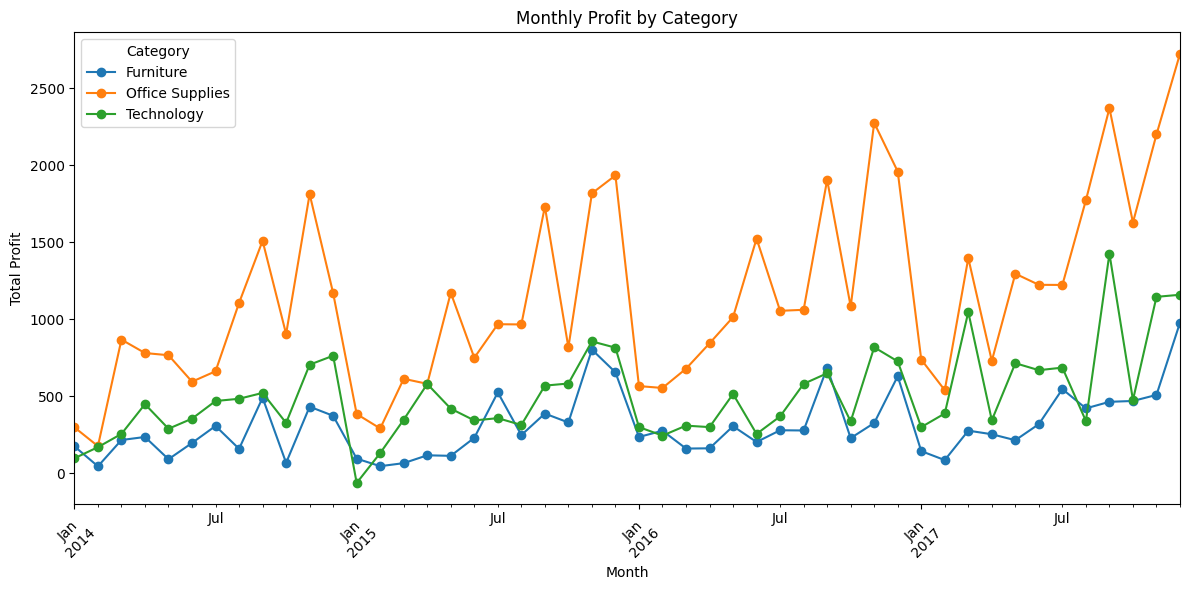

In [30]:
monthly_category_profit = (
    cleaned_df.dropna(subset=["Order Date"])
    .groupby([
        pd.Grouper(key="Order Date", freq="ME"),
        "Category"
    ])["Profit"]
    .sum()
    .unstack()
)

fig, ax = plt.subplots(figsize=(12, 6))

monthly_category_profit.plot(ax=ax, marker="o")

ax.set_title("Monthly Profit by Category")
ax.set_xlabel("Month")
ax.set_ylabel("Total Profit")
ax.legend(title="Category")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 3.6: `HEAT Map`

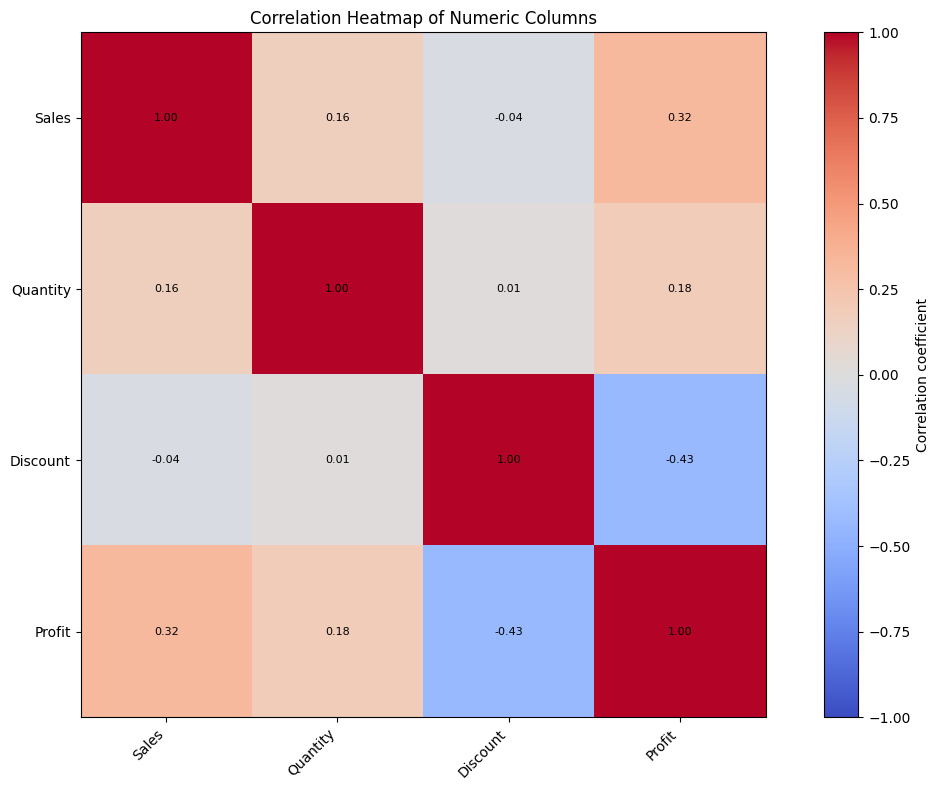

In [40]:
numeric_df = cleaned_df.drop(columns=["Postal Code"]).select_dtypes(include="number")

corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(12, 8))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")

ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Correlation coefficient")
ax.set_title("Correlation Heatmap of Numeric Columns")

plt.tight_layout()
plt.savefig('heatmap.png',dpi=300, bbox_inches='tight')
plt.show()


# 4: `Make one chart better`.
 Pick your favourite chart and improve it: a clear title, readable axis labels, sensible colours, and categories in a logical order.

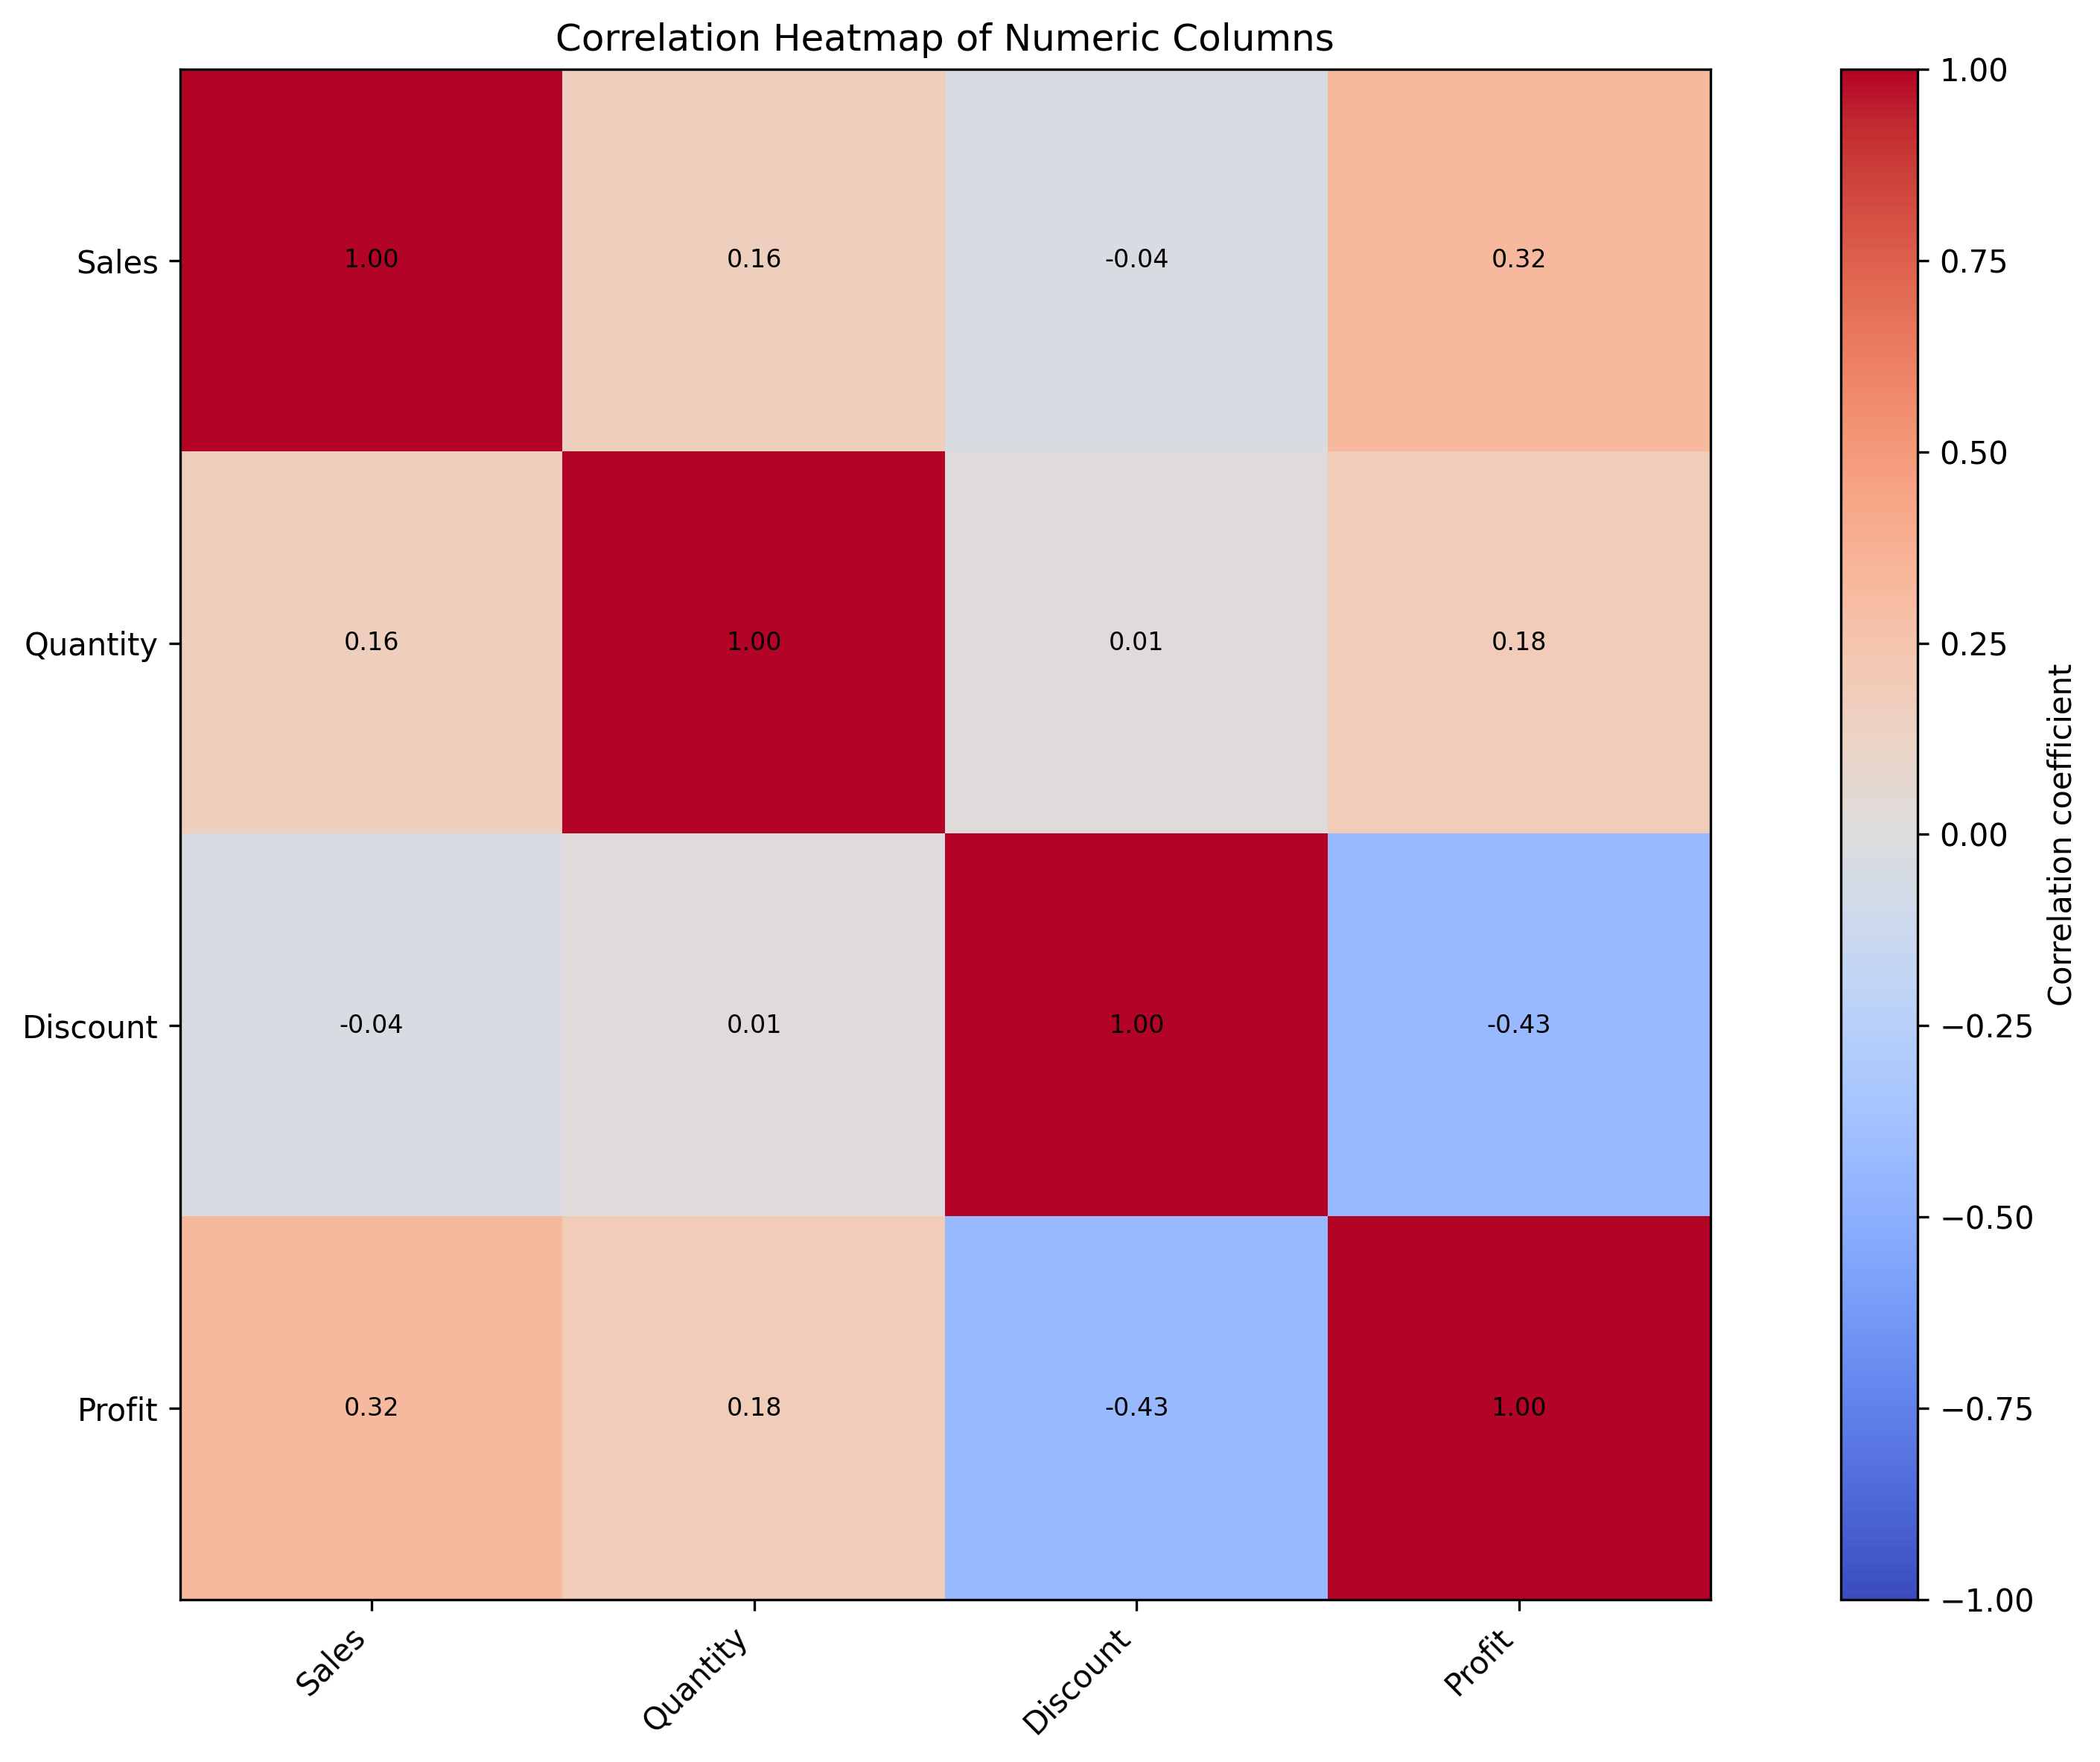


## 4.1: 📊 Key Findings from the Correlation Heatmap

- 📈 **Sales vs. Profit:** Higher sales generally tend to be associated with higher profit.

- 📦 **Quantity vs. Profit:** Higher quantities sold show a slight positive relationship with profit.

- 🏷️ **Discount vs. Profit:** Higher discounts tend to be associated with lower profit and may contribute to losses.

---

### 💡 Key Insight
Increasing sales and quantity can support profitability, but excessive discounting may reduce profit margins.

> **Note:** Correlation indicates a relationship between variables; it does not necessarily prove causation.
